In [1]:
%pip install kaggle

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 181.2/181.2 KB 1.3 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.2/78.2 KB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 165.1/165.1 KB 4.4 MB/s eta 0:00:0000:01
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install kagglehub

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.6/70.6 KB 759.3 kB/s eta 0:00:00 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 230.0/230.0 KB 2.5 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install pandas numpy matplotlib seaborn scikit-learn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 43.9 MB/s eta 0:00:0000:0100:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 49.0 MB/s eta 0:00:0000:0100:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 KB 9.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 46.8 MB/s eta 0:00:0000:0100:01m
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 348.0/348.0 KB 16.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 506.3/506.3 KB 21.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 325.0/325.0 KB 3.0 MB/s eta 0:00:0000:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 45.1 MB/s eta 0:00:00:00:01
  Using cached fonttools-4.65.0-cp310-cp310-manylinux2014_x86_64.manylinux_2_17_x86_64.whl (5.3 MB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 44.1 MB/s eta 0:00:0000:01:00:01
  Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 306.1/306.1 KB 15.6 MB/s

In [4]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


%pip install kagglehub

In [5]:
import os
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from pathlib import Path
from PIL import Image
import kagglehub
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


2026-10-23 11:23:33.826956: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1792754613.847178    1435 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792754613.852994    1435 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792754613.871177    1435 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792754613.871197    1435 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792754613.871199    1435 computation_placer.cc:177] computation placer alr

In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

100%|██████████| 2.29G/2.29G [00:56<00:00, 43.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [7]:
splits=[]
types=[]
print("Dataset path:", path)
print("\nDataset structure:")

for item in os.listdir(path):
    item_path = os.path.join(path, item)

    if os.path.isdir(item_path):
        print(f"Folder:  {item}/")
    else:
        print(f"File {item}")

# print(os.listdir(path))
for ele in os.listdir(path + "/chest_xray"):
  if ele =="chest_xray" or ele =="__MACOSX":
    continue
  splits.append(ele)

for split in splits:
  t=os.listdir(path + "/chest_xray/" + split)
  for ele in t:
    if ele in types:
      continue
    types.append(ele)
print(splits)
print(types)


Dataset path: /root/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2

Dataset structure:
Folder:  chest_xray/
['test', 'train', 'val']
['NORMAL', 'PNEUMONIA']


In [8]:
from pathlib import Path
from PIL import Image

root = Path(path)
IMG_SIZE = (180, 180)

for split in splits:
    split_path = root / "chest_xray" / split

    if split_path.exists():
        print(f"\n{split}")

        for class_name in types:
            class_path = split_path / class_name

            if class_path.exists():

                images = []

                for f in class_path.iterdir():
                    if f.is_file():
                        images.append(f)

                print(f"{class_name}: {len(images)} images")

                processed_images = []

                for image_path in images:
                    try:
                        with Image.open(image_path) as image:
                            image = image.convert("RGB")
                            image = image.resize(IMG_SIZE)

                            processed_images.append(image.copy())

                    except Exception as e:
                        print(f"Erreur avec {image_path}: {e}")

                print(
                    f"Images traitées: {len(processed_images)}"
                )


test
NORMAL: 234 images
Images traitées: 234
PNEUMONIA: 390 images
Images traitées: 390

train
NORMAL: 1341 images
Images traitées: 1341
PNEUMONIA: 3875 images
Images traitées: 3875

val
NORMAL: 8 images
Images traitées: 8
PNEUMONIA: 8 images
Images traitées: 8



NORMAL: 4 images



PNEUMONIA: 4 images


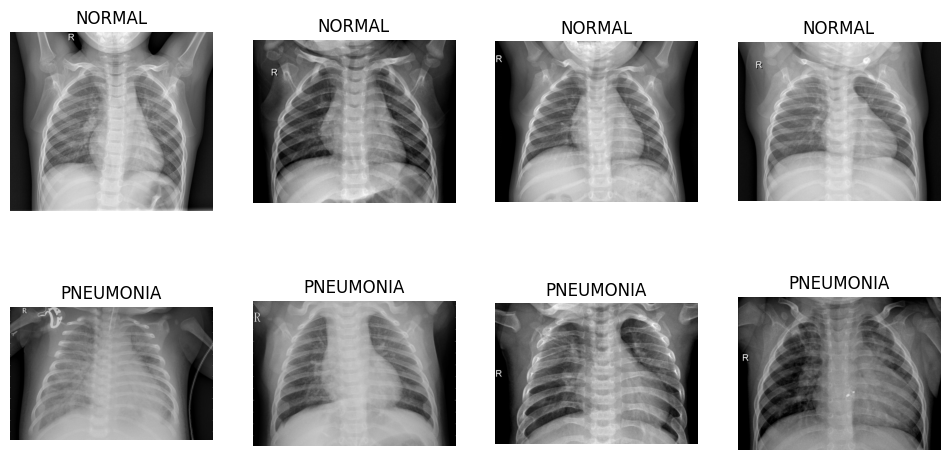

In [9]:
train_dir = Path(path) / "chest_xray" / "train"

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for row, class_name in enumerate(types):
    images = list((train_dir / class_name).glob("*.jpeg"))[:4]
    print(f"\n{class_name}: {len(images)} images")
    for col, img_path in enumerate(images):
        axes[row, col].imshow(Image.open(img_path), cmap="gray")
        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.show()

NORMAL: 1341 images (25.7%)
PNEUMONIA: 3875 images (74.3%)


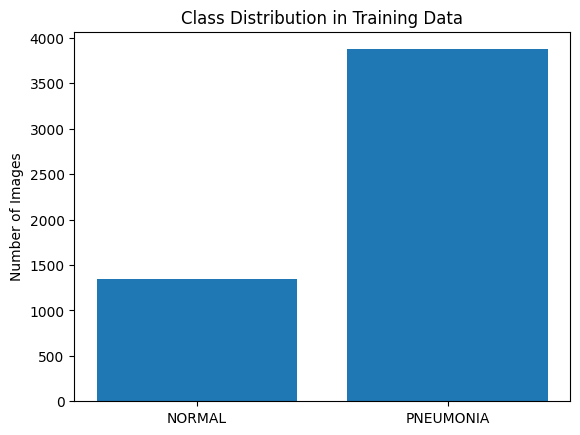

In [10]:
train_dir = Path(path) / "chest_xray" / "train"

counts = {
    name: len(list((train_dir / name).glob("*.jpeg")))
    for name in types
}
total = sum(counts.values())

for name, n in counts.items():
    print(f"{name}: {n} images ({n / total * 100:.1f}%)")

plt.bar(counts.keys(), counts.values())
plt.title("Class Distribution in Training Data")
plt.ylabel("Number of Images")
plt.show()

In [11]:
classes = np.array([0, 1])   # 0 = NORMAL, 1 = PNEUMONIA
y_train = np.array([0] * counts["NORMAL"] + [1] * counts["PNEUMONIA"])

weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight_dict = {int(c): float(w) for c, w in zip(classes, weights)}

print("Class weights:", class_weight_dict)
print("Class weights:", class_weight_dict)

Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}
Class weights: {0: 1.9448173005219984, 1: 0.6730322580645162}


In [12]:
from pathlib import Path
from PIL import Image

valid_images = []
corrupted_images = []

for split in splits:
    for class_name in types:
        class_path = root / "chest_xray" / split / class_name

        if not class_path.exists():
            print(f"Dossier introuvable : {class_path}")
            continue

        for img_path in class_path.iterdir():
            if not img_path.is_file():
                continue

            try:
                with Image.open(img_path) as img:
                    img.verify()

                valid_images.append(img_path)

            except Exception as e:
                corrupted_images.append(img_path)
                print(f"Image invalide : {img_path} | Erreur : {e}")

print("Images valides :", len(valid_images))
print("Images corrompues :", len(corrupted_images))

Images valides : 5856
Images corrompues : 0


In [13]:
train_dir = Path(path) / "chest_xray" / "train"
test_dir = Path(path) / "chest_xray" / "test"

CLASS_NAMES=["NORMAL", "PNEUMONIA"]
SEED=42

common = dict(
    class_names=CLASS_NAMES,
    label_mode="binary",
    image_size=IMG_SIZE,
    batch_size=32,
)

train_ds_cnn = tf.keras.utils.image_dataset_from_directory(
    train_dir, validation_split=0.2,
    subset="training",
    seed=SEED,
    **common)

val_ds_cnn = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    **common)

test_ds_cnn = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,
    **common)

print("Classes:", train_ds_cnn.class_names)


Found 5216 files belonging to 2 classes.
Using 4173 files for training.


I0000 00:00:1792754768.528537    1435 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 22365 MB memory:  -> device: 0, name: NVIDIA RTX A5000, pci bus id: 0000:61:00.0, compute capability: 8.6


Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.
Classes: ['NORMAL', 'PNEUMONIA']


In [14]:
# Normalisation des pixels entre 0 et 1
normalization_layer = tf.keras.layers.Rescaling(1.0 / 255)

train_ds = train_ds_cnn.map(
    lambda images, labels: (normalization_layer(images), labels)
)

val_ds = val_ds_cnn.map(
    lambda images, labels: (normalization_layer(images), labels)
)

test_ds = test_ds_cnn.map(
    lambda images, labels: (normalization_layer(images), labels)
)

In [15]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

In [16]:
# Evaluation helper: used for the CNN, transfer learning and fine-tuning
results = {}


def evaluate_classifier(name, model, dataset, threshold=0.5):
    y_true = []
    y_prob = []

    for images, labels in dataset:
        probabilities = model.predict(images, verbose=0)
        y_prob.extend(probabilities.ravel())
        y_true.extend(labels.numpy().ravel())

    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    y_pred = (y_prob >= threshold).astype(int)

    metrics = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "recall": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "roc_auc": roc_auc_score(y_true, y_prob),
    }

    results[name] = {
        "metrics": metrics,
        "y_true": y_true,
        "y_prob": y_prob,
        "y_pred": y_pred,
    }

    print(f"\n{name}")
    for metric_name, value in metrics.items():
        print(f"{metric_name.replace('_', '-').title()}: {value:.4f}")

    return results[name]


In [17]:

# 13. Construire le modèle CNN
model_cnn = models.Sequential([
    # Input
    layers.Input(shape=(180, 180, 3)),

    # Block 1
    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 2
    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Block 3
    layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    # Classification
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.5),

    # Binary output
    layers.Dense(1, activation="sigmoid")
])

model_cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

In [18]:
import tensorflow as tf
# 14. Compiler et entraîner le modèle
# Compile the model
model_cnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)



In [19]:
# Train the model
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "best_chestscan_cnn.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

history = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=callbacks
)

Epoch 1/15


I0000 00:00:1792754772.775756    1705 service.cc:152] XLA service 0x7ff2fc005120 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792754772.775788    1705 service.cc:160]   StreamExecutor device (0): NVIDIA RTX A5000, Compute Capability 8.6
2026-10-23 11:26:14.170682: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792754775.471438    1705 cuda_dnn.cc:529] Loaded cuDNN version 90300


 16/131 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.3546 - loss: 0.7275 - precision: 0.6898 - recall: 0.1486

I0000 00:00:1792754780.581062    1705 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


126/131 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.4208 - loss: 0.6988 - precision: 0.7754 - recall: 0.2809

2026-10-23 11:26:25.275057: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_346', 8 bytes spill stores, 8 bytes spill loads



131/131 ━━━━━━━━━━━━━━━━━━━━ 20s 86ms/step - accuracy: 0.4254 - loss: 0.6974 - precision: 0.7788 - recall: 0.2875 - val_accuracy: 0.6385 - val_loss: 0.6257 - val_precision: 0.8664 - val_recall: 0.6209
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.6573 - loss: 0.5908 - precision: 0.9095 - recall: 0.5913 - val_accuracy: 0.6242 - val_loss: 0.5481 - val_precision: 0.9258 - val_recall: 0.5504
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.6833 - loss: 0.5164 - precision: 0.9451 - recall: 0.6021 - val_accuracy: 0.8533 - val_loss: 0.3242 - val_precision: 0.9598 - val_recall: 0.8426
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.8329 - loss: 0.3516 - precision: 0.9597 - recall: 0.8029 - val_accuracy: 0.8485 - val_loss: 0.3354 - val_precision: 0.9804 - val_recall: 0.8174
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.8698 - loss: 0.2906 - precision: 0.9683 - recall: 0.8493 - val_accuracy: 0.9051 - val_loss: 0.2313 

In [20]:
# Normal CNN evaluation
Normal_CNN=evaluate_classifier("Normal CNN", model_cnn, test_ds_cnn)

Normal_CNN

2026-10-23 11:27:49.395081: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_70', 4 bytes spill stores, 4 bytes spill loads




Normal CNN
Accuracy: 0.6699
Precision: 0.9510
Recall: 0.4974
F1: 0.6532
Roc-Auc: 0.7576


2026-10-23 11:27:50.065912: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


{'metrics': {'accuracy': 0.6698717948717948,
  'precision': 0.9509803921568627,
  'recall': 0.49743589743589745,
  'f1': 0.6531986531986532,
  'roc_auc': 0.7575827306596538},
 'y_true': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,

Transfer Learming Steps

In [21]:
# Step 1 — Prepare the dataset
AUTOTUNE = tf.data.AUTOTUNE

common_mn = dict(
    class_names=CLASS_NAMES,
    label_mode="binary",
    image_size=(224, 224),
    batch_size=32,
)

train_ds_mn = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    **common_mn)

val_ds_mn = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    **common_mn
    )
test_ds_mn = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    shuffle=False,
    **common_mn)

train_ds_mn = train_ds_mn.map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)
val_ds_mn   = val_ds_mn.map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)
test_ds_mn  = test_ds_mn.map(lambda x, y: (preprocess_input(x), y)).prefetch(AUTOTUNE)

Found 5216 files belonging to 2 classes.
Using 4173 files for training.
Found 5216 files belonging to 2 classes.
Using 1043 files for validation.
Found 624 files belonging to 2 classes.


In [22]:
# Step 2 — Load the pretrained model
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Step 3 — Freeze the pretrained layers
base_model.trainable = False

# Step 4 — Add a new classifier
inputs = layers.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

model_mn = models.Model(inputs, outputs)



9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [23]:
# Step 5 - Compile and train the classifier head (base frozen)
base_model.trainable = False

model_mn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

callbacks_mn = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss",
                                      patience=3,
                                      restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_mobilenetv2_tl.keras",
                                        monitor="val_loss",
                                        save_best_only=True)
]

history_mn = model_mn.fit(
    train_ds_mn,
    validation_data=val_ds_mn,
    epochs=15,
    class_weight=class_weight_dict,
    callbacks=callbacks_mn
)

# Step 6 - Evaluate transfer learning alone (base frozen)
# This happens BEFORE unfreezing, so the metrics belong to the frozen model.
TR_learning=evaluate_classifier("Transfer Learning (frozen)", model_mn, test_ds_mn)
print(TR_learning)
model_mn.save("best_mobilenetv2_tl.keras")

# Step 7 - Unfreeze the last 20 layers of MobileNetV2 (fine-tuning)
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

# Step 8 - Recompile model_mn with a very low learning rate, then fine-tune
model_mn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

callbacks_ft = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    tf.keras.callbacks.ModelCheckpoint("best_mobilenetv2_ft.keras", monitor="val_loss", save_best_only=True)
]

history_ft = model_mn.fit(
    train_ds_mn,
    validation_data=val_ds_mn,
    epochs=10,
    class_weight=class_weight_dict,
    callbacks=callbacks_ft
)

# Step 9 - Evaluate fine-tuning alone
Fine_tuning=evaluate_classifier("Fine-Tuning", model_mn, test_ds_mn)
Fine_tuning


Epoch 1/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 0s 57ms/step - accuracy: 0.8100 - loss: 0.4213 - precision: 0.9199 - recall: 0.8034

2026-10-23 11:28:11.877660: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1181_0', 464 bytes spill stores, 1372 bytes spill loads

2026-10-23 11:28:11.943352: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1181', 204 bytes spill stores, 204 bytes spill loads

2026-10-23 11:28:12.422141: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1181', 5616 bytes spill stores, 5612 bytes spill loads

2026-10-23 11:28:12.531438: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1181', 5340 bytes spill stores, 5324 bytes spill loads

2026-10-23 11:28:15.69404

131/131 ━━━━━━━━━━━━━━━━━━━━ 27s 143ms/step - accuracy: 0.8106 - loss: 0.4200 - precision: 0.9202 - recall: 0.8040 - val_accuracy: 0.9540 - val_loss: 0.1169 - val_precision: 0.9882 - val_recall: 0.9509
Epoch 2/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - accuracy: 0.9477 - loss: 0.1353 - precision: 0.9809 - recall: 0.9470 - val_accuracy: 0.9636 - val_loss: 0.0907 - val_precision: 0.9821 - val_recall: 0.9698
Epoch 3/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 48ms/step - accuracy: 0.9560 - loss: 0.1148 - precision: 0.9888 - recall: 0.9505 - val_accuracy: 0.9338 - val_loss: 0.1579 - val_precision: 0.9959 - val_recall: 0.9169
Epoch 4/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 6s 49ms/step - accuracy: 0.9524 - loss: 0.1146 - precision: 0.9889 - recall: 0.9451 - val_accuracy: 0.9358 - val_loss: 0.1395 - val_precision: 0.9959 - val_recall: 0.9194
Epoch 5/15
131/131 ━━━━━━━━━━━━━━━━━━━━ 7s 52ms/step - accuracy: 0.9583 - loss: 0.0961 - precision: 0.9883 - recall: 0.9540 - val_accuracy: 0.9655 - val_loss: 0.0783

2026-10-23 11:29:31.885052: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1150', 4 bytes spill stores, 4 bytes spill loads

2026-10-23 11:29:32.175364: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1150_0', 200 bytes spill stores, 536 bytes spill loads

2026-10-23 11:29:32.376064: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1150', 116 bytes spill stores, 116 bytes spill loads

2026-10-23 11:29:32.831289: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_1150', 5616 bytes spill stores, 5612 bytes spill loads

2026-10-23 11:29:33.104592: I ex


Transfer Learning (frozen)
Accuracy: 0.8141
Precision: 0.7729
Recall: 0.9949
F1: 0.8700
Roc-Auc: 0.9632
{'metrics': {'accuracy': 0.8141025641025641, 'precision': 0.7729083665338645, 'recall': 0.9948717948717949, 'f1': 0.8699551569506726, 'roc_auc': 0.9632204689896997}, 'y_true': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
       0., 0., 0., 0., 0., 0., 0., 0., 0., 0

{'metrics': {'accuracy': 0.8333333333333334,
  'precision': 0.7930327868852459,
  'recall': 0.9923076923076923,
  'f1': 0.8815489749430524,
  'roc_auc': 0.9632095112864344},
 'y_true': array([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 

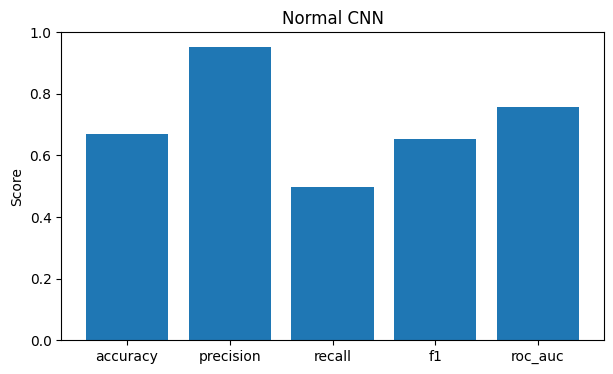

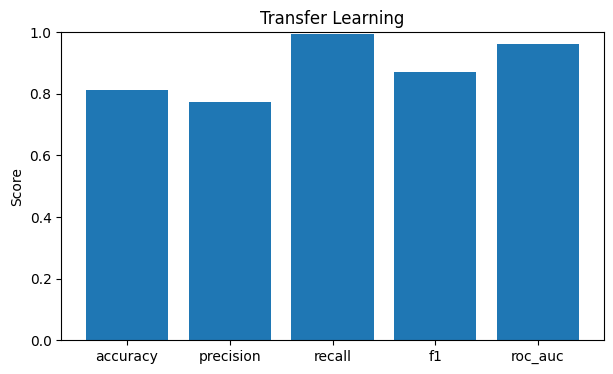

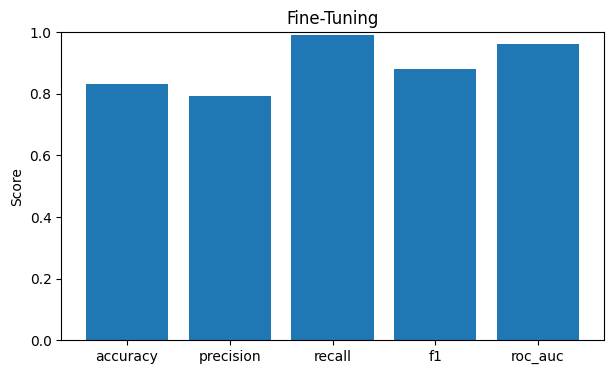

In [38]:
models = [Normal_CNN, TR_learning, Fine_tuning]
names = ["Normal CNN", "Transfer Learning", "Fine-Tuning"]


for name, m in zip(names, models):
    plt.figure(figsize=(7, 4))
    plt.bar(list(m["metrics"].keys()), list(m["metrics"].values()))
    plt.ylim(0, 1)
    plt.title(name)
    plt.ylabel("Score")
    plt.show()


In [ ]:
model_cnn.save("chestscan_cnn.keras")
model_mn.save("chestscan_mobilenetv2.keras")


In [27]:
import json

metadata = {
    "image_size": [224, 224],
    "class_names": ["NORMAL", "PNEUMONIA"],
    "preprocessing": "mobilenet_v2_preprocess_input",
    "pixel_range_after_preprocessing": [-1, 1],
    "threshold": 0.5
}

with open("chestscan_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Modèles et métadonnées sauvegardés.")


with open("chestscan_metadata.json", "r") as file:
    metadata = json.load(file)

print(metadata)

Modèles et métadonnées sauvegardés.
{'image_size': [224, 224], 'class_names': ['NORMAL', 'PNEUMONIA'], 'preprocessing': 'mobilenet_v2_preprocess_input', 'pixel_range_after_preprocessing': [-1, 1], 'threshold': 0.5}
